# Advanced Array Mathematics & Array Transformations

**Learning outcomes**
CPMK 3. Able to process and analyze data using existing software packages.

**Instructions:** Run the code cells in order. Read the explanations and complete the independent exercises before reading the answer key.

`broadcasting` `np.broadcast_shapes()` `.shape` `reshape()` `keepdims=True` `np.save()` `np.load()` `.npy` `dtype` `uint8` `np.clip()` `np.flip()` `.T` `np.transpose()` `np.swapaxes()` `np.split()` `np.array_split()` `np.stack()` `np.concatenate()`

## Table of Contents

1. Broadcasting in NumPy
2. Saving and Loading Arrays
3. Image Arrays and Transformations
4. Transposing Arrays
5. Stacking and Splitting Arrays
6. Independent Student Exercises
7. Meeting Summary and Self-Assessment

In [2]:
# Install NumPy (jika belum, hapus # pada baris berikut)
# %pip install numpy

In [3]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.4.6


---
## 1. Broadcasting in NumPy

### 1.1 Introduction to Broadcasting

**Broadcasting** memungkinkan operasi antar-array dengan bentuk (*shape*) berbeda tanpa mengulang data secara manual. NumPy menyesuaikan dimensi yang kompatibel saat melakukan operasi **element-wise**. Contoh paling sederhana adalah menambahkan satu bilangan ke seluruh elemen array.

In [4]:
measurements = np.array([10, 20, 30, 40])
correction = 5

print("Original:", measurements)
print("Correction:", correction)
print("After broadcasting:", measurements + correction)
print("Original remains:", measurements)

Original: [10 20 30 40]
Correction: 5
After broadcasting: [15 25 35 45]
Original remains: [10 20 30 40]


### 1.2 Broadcasting Rules

NumPy memeriksa ukuran setiap dimensi array dari kanan ke kiri. Dua array dapat dioperasikan jika ukuran dimensinya **sama** atau **salah satunya bernilai** 1. Jika suatu dimensi tidak ada, NumPy menganggap ukurannya 1. Jika ukuran dimensi tidak memenuhi aturan tersebut, operasi akan gagal dan muncul pesan kesalahan `ValueError`.

In [5]:
matrix = np.array([[10, 20, 30],
                   [40, 50, 60]])
row_adjustment = np.array([1, 2, 3])

print("Matrix shape:", matrix.shape)
print("Adjustment shape:", row_adjustment.shape)
print("Broadcast result shape:", (matrix + row_adjustment).shape)
print(matrix + row_adjustment)

# Contoh yang tidak kompatibel: (2, 3) dan (2,)
incompatible = np.array([1, 2])
try:
    print(matrix + incompatible)
except ValueError as error:
    print("Incompatible shapes:", error)

Matrix shape: (2, 3)
Adjustment shape: (3,)
Broadcast result shape: (2, 3)
[[11 22 33]
 [41 52 63]]
Incompatible shapes: operands could not be broadcast together with shapes (2,3) (2,) 


### 1.3 Shape Compatibility

Bentuk `(3, 1)` memiliki 3 baris dan 1 kolom, sedangkan `(1, 4)` memiliki 1 baris dan 4 kolom. Melalui broadcasting, NumPy secara otomatis menyesuaikan dimensi berukuran 1, sehingga menghasilkan bentuk `(3, 4)`. Fungsi `np.broadcast_shapes()` digunakan untuk memeriksa bentuk hasil sebelum operasi dilakukan.

In [6]:
column_vector = np.array([[10],
                          [20],
                          [30]])
row_vector = np.array([[1, 2, 3, 4]])

combined = column_vector + row_vector

print("Column shape:", column_vector.shape)
print("Row shape:", row_vector.shape)
print("Compatible result shape:", np.broadcast_shapes(column_vector.shape, row_vector.shape))
print("Combined array:")
print(combined)

Column shape: (3, 1)
Row shape: (1, 4)
Compatible result shape: (3, 4)
Combined array:
[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]]


### 1.4 Broadcasting Across Rows and Columns

Pada array 2D, kita dapat menambahkan nilai yang berbeda untuk setiap **kolom** menggunakan vektor berbentuk `(n_columns,)`. Jika ingin menambahkan nilai yang berbeda untuk setiap **baris**, gunakan `reshape(-1, 1)` untuk mengubah vektor menjadi bentuk `(n_rows, 1)`.

In [7]:
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

column_bonus = np.array([2, 3, 5])
row_bonus = np.array([1, 4, 2]).reshape(-1, 1)

print("Bonus per column (applies to each row):")
print(scores + column_bonus)
print("Bonus per row (applies to each column):")
print(scores + row_bonus)
print("Row bonus shape:", row_bonus.shape)

Bonus per column (applies to each row):
[[ 72  83  95]
 [ 77  88 100]
 [ 62  73  85]]
Bonus per row (applies to each column):
[[71 81 91]
 [79 89 99]
 [62 72 82]]
Row bonus shape: (3, 1)


**Applied example: Centering by Column Mean**

Untuk mengurangi setiap nilai data dengan **rata-rata kolomnya**, gunakan `np.mean(..., axis=0, keepdims=True)`. Hasil rata-rata berbentuk `(1, n_columns)`, sehingga melalui **broadcasting**, setiap nilai pada kolom akan dikurangi dengan rata-rata kolom tersebut.

In [8]:
variable_means = np.mean(scores, axis=0, keepdims=True)
centered_scores = scores - variable_means

print("Column means:", variable_means)
print("Column means shape:", variable_means.shape)
print("Centered scores:")
print(centered_scores)
print("Means after centering:", np.mean(centered_scores, axis=0))

Column means: [[68.33333333 78.33333333 88.33333333]]
Column means shape: (1, 3)
Centered scores:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]
Means after centering: [4.73695157e-15 4.73695157e-15 4.73695157e-15]


**Common mistakes:** Array berbentuk `(3,)` tidak otomatis dianggap sebagai kolom `(3, 1)`. NumPy membandingkan ukuran dimensi dari **kanan ke kiri**. Jika ingin menggunakan nilai yang berbeda untuk setiap **baris**, ubah bentuk array menjadi `(3, 1)` menggunakan `reshape(-1, 1)`.

---
## 2. Saving and Loading Arrays

### 2.1 Working with `.npy` Files

File **`.npy`** adalah format biner NumPy untuk menyimpan **satu array** beserta informasi `shape` dan `dtype`. File ini dapat dibuka kembali tanpa mengetik ulang data. Pada contoh berikut, file dibuat di folder kerja notebook agar bisa digunakan pada bagian selanjutnya.

In [9]:
rainfall_data = np.array([[12.5, 8.0, 5.5],
                          [10.0, 15.5, 7.0],
                          [20.0, 11.0, 9.5]])

# Menyiapkan file untuk contoh loading pada subsection berikutnya
np.save("week11_rainfall.npy", rainfall_data)
print("Prepared file: week11_rainfall.npy")
print("Original shape:", rainfall_data.shape)
print("Original dtype:", rainfall_data.dtype)

Prepared file: week11_rainfall.npy
Original shape: (3, 3)
Original dtype: float64


**Silahkan buka folder dan temukan week11_rainfall.npy**

### 2.2 Loading Arrays (`np.load`)

Gunakan **`np.load("nama_file.npy")`** untuk membaca array yang tersimpan. File harus berada di lokasi yang sesuai dengan path yang digunakan. `allow_pickle=False` dipakai untuk membatasi pemuatan objek Python yang tidak diperlukan dalam contoh numerik ini.

In [11]:
loaded_rainfall = np.load("week11_rainfall.npy", allow_pickle=False)

print("Loaded rainfall:")
print(loaded_rainfall)
print("Loaded shape:", loaded_rainfall.shape)

Loaded rainfall:
[[12.5  8.   5.5]
 [10.  15.5  7. ]
 [20.  11.   9.5]]
Loaded shape: (3, 3)


### 2.3 Saving Arrays (`np.save`)

`np.save("file.npy", array)` menyimpan array NumPy ke file `.npy`. Contoh ini menyimpan data nilai ujian dalam file baru. Gunakan nama berbeda agar file yang telah dibuat sebelumnya tidak tertimpa.

In [12]:
exam_scores = np.array([[80, 85, 90],
                        [70, 75, 80],
                        [90, 92, 94]])

np.save("week11_exam_scores.npy", exam_scores)
print("Saved file: week11_exam_scores.npy")
print("Saved array:")
print(exam_scores)

Saved file: week11_exam_scores.npy
Saved array:
[[80 85 90]
 [70 75 80]
 [90 92 94]]


### 2.4 Inspecting Loaded Arrays

Setelah data dibuka, periksa `.shape`, `.ndim`, dan `.dtype` untuk memastikan struktur tetap sesuai. `np.array_equal()` membandingkan kesamaan nilai serta bentuk array sebelum dan setelah penyimpanan.

In [13]:
loaded_scores = np.load("week11_exam_scores.npy", allow_pickle=False)

print("Shape:", loaded_scores.shape)
print("Number of dimensions:", loaded_scores.ndim)
print("Data type:", loaded_scores.dtype)
print("First student's scores:", loaded_scores[0, :])
print("Same values and shape:", np.array_equal(exam_scores, loaded_scores))

Shape: (3, 3)
Number of dimensions: 2
Data type: int64
First student's scores: [80 85 90]
Same values and shape: True


**Important distinction:** `.npy` mempertahankan bentuk dan tipe data array NumPy, tetapi bukan format tabel dengan nama kolom seperti CSV. Gunakan `np.load()` hanya untuk file dari sumber, terutama jika suatu saat bekerja dengan array bertipe `object`.

---
## 3. Image Arrays and Transformations

### 3.1 Understanding RGB and RGBA Arrays

Gambar berwarna dapat direpresentasikan sebagai array 3D dengan bentuk **`(height, width, channels)`**. **RGB** memiliki 3 kanal (Red, Green, Blue); **RGBA** memiliki kanal keempat, yaitu Alpha (transparansi). Pada gambar 8-bit, nilai tiap kanal biasanya berada pada rentang **0 sampai 255**.

In [14]:
# Gambar RGB sederhana: 3 baris x 3 kolom x 3 kanal warna
rgb_image = np.array([
    [[255, 0, 0],   [0, 255, 0],   [0, 0, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0]]
], dtype=np.uint8)

alpha_channel = np.full((*rgb_image.shape[:2], 1), 255, dtype=np.uint8)
rgba_image = np.concatenate((rgb_image, alpha_channel), axis=2)

print("RGB shape:", rgb_image.shape)
print("RGBA shape:", rgba_image.shape)
print("Top-left RGB pixel:", rgb_image[0, 0])
print("Top-left RGBA pixel:", rgba_image[0, 0])

RGB shape: (3, 3, 3)
RGBA shape: (3, 3, 4)
Top-left RGB pixel: [255   0   0]
Top-left RGBA pixel: [255   0   0 255]


### 3.2 Selecting Image Color Channels

Gunakan `image[:, :, 0]` untuk kanal **Red**, indeks `1` untuk **Green**, dan indeks `2` untuk **Blue**. Setelah memilih satu kanal, hasilnya menjadi array **2D** `(height, width)`. Pemilihan `image[:, :, 0:1]` mempertahankan dimensi kanal.

In [15]:
red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]

print("Red channel:")
print(red_channel)
print("Green channel:")
print(green_channel)
print("Blue channel:")
print(blue_channel)
print("Red shape:", red_channel.shape)
print("Red shape with 0:1:", rgb_image[:, :, 0:1].shape)

Red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Green channel:
[[  0 255   0]
 [255 255   0]
 [255 128   0]]
Blue channel:
[[  0   0 255]
 [  0 255 255]
 [255 128   0]]
Red shape: (3, 3)
Red shape with 0:1: (3, 3, 1)


### 3.3 Manipulating Pixel Values

Nilai piksel dapat diubah dengan operasi NumPy, misalnya meningkatkan kecerahan atau mengurangi salah satu kanal. Karena `uint8` hanya menampung nilai 0–255, ubah dahulu ke tipe bilangan yang lebih besar sebelum penjumlahan, kemudian batasi hasil dengan **`np.clip()`** agar tidak terjadi *overflow*.

In [16]:
# Gunakan tipe lebih besar untuk menghindari overflow uint8
brightened_image = np.clip(rgb_image.astype(np.int16) + 40, 0, 255).astype(np.uint8)

less_red_image = rgb_image.copy()
less_red_image[:, :, 0] = 0

print("Original pixel [1, 1]:", rgb_image[1, 1])
print("Brighter pixel [1, 1]:", brightened_image[1, 1])
print("Original pixel [0, 0]:", rgb_image[0, 0])
print("Pixel without red [0, 0]:", less_red_image[0, 0])
print("Original image remains:", rgb_image[0, 0])

Original pixel [1, 1]: [  0 255 255]
Brighter pixel [1, 1]: [ 40 255 255]
Original pixel [0, 0]: [255   0   0]
Pixel without red [0, 0]: [0 0 0]
Original image remains: [255   0   0]


### 3.4 Flipping Arrays (`np.flip`)

`np.flip(image, axis=0)` membalik posisi **atas–bawah** (vertikal), sedangkan `axis=1` membalik posisi **kiri–kanan** (horizontal). Pada gambar RGB, sumbu `2` adalah kanal warna, sehingga membalik `axis=2` justru mengubah urutan kanal, bukan orientasi gambar.

In [17]:
vertical_flip = np.flip(rgb_image, axis=0)
horizontal_flip = np.flip(rgb_image, axis=1)

print("Original red channel:")
print(rgb_image[:, :, 0])
print("Vertical flip (axis=0):")
print(vertical_flip[:, :, 0])
print("Horizontal flip (axis=1):")
print(horizontal_flip[:, :, 0])
print("Flipped shape:", horizontal_flip.shape)

Original red channel:
[[255   0   0]
 [255   0 255]
 [255 128   0]]
Vertical flip (axis=0):
[[255 128   0]
 [255   0 255]
 [255   0   0]]
Horizontal flip (axis=1):
[[  0   0 255]
 [255   0 255]
 [  0 128 255]]
Flipped shape: (3, 3, 3)


**Optional Visualization**

Kode berikut menampilkan gambar sintetis tanpa mengunduh file dari internet. Bagian ini memakai `matplotlib` sebagai bantuan visual; konsep transformasinya tetap menggunakan NumPy.

In [18]:
# Opsional untuk menampilkan gambar pada contoh Section 3:
# %pip install matplotlib

In [19]:
import matplotlib
print("Matplotlib version:", matplotlib.__version__)

Matplotlib version: 3.11.0


Matplotlib is building the font cache; this may take a moment.


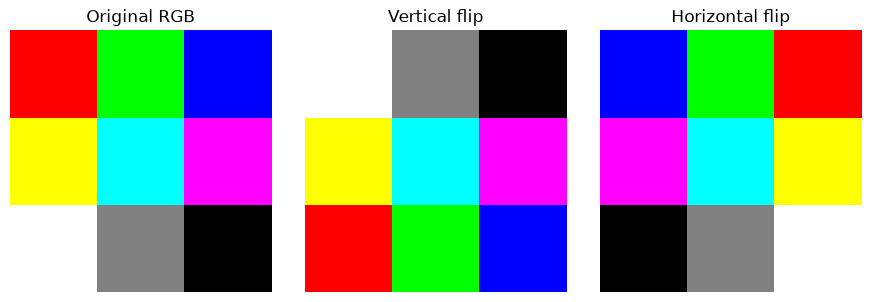

In [20]:
try:
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 3, figsize=(9, 3))
    for axis, picture, label in zip(
        axes,
        [rgb_image, vertical_flip, horizontal_flip],
        ["Original RGB", "Vertical flip", "Horizontal flip"]
    ):
        axis.imshow(picture)
        axis.set_title(label)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib belum terpasang. instal matplotlib.")

---
## 4. Transposing Arrays

### 4.1 Array Transposition

**Transposition** menukar susunan sumbu array. Untuk matriks 2D, `.T` atau `np.transpose()` mengubah baris menjadi kolom dan sebaliknya: `(rows, columns)` menjadi `(columns, rows)`. Pada array 1D, `.T` tidak mengubah bentuknya.

In [21]:
data_matrix = np.array([[1, 2, 3],
                        [4, 5, 6]])

print("Original:")
print(data_matrix)
print("Shape:", data_matrix.shape)
print("Transposed:")
print(data_matrix.T)
print("Transposed shape:", np.transpose(data_matrix).shape)
print("1D transpose shape:", np.array([1, 2, 3]).T.shape)

Original:
[[1 2 3]
 [4 5 6]]
Shape: (2, 3)
Transposed:
[[1 4]
 [2 5]
 [3 6]]
Transposed shape: (3, 2)
1D transpose shape: (3,)


### 4.2 Transposing by Axis

Untuk array 3D atau lebih, `np.transpose(array, axes=(...))` menentukan **urutan baru semua sumbu**. Misalnya, `(0, 1, 2)` menjadi `(1, 0, 2)` berarti menukar sumbu pertama dan kedua. `np.swapaxes()` dapat dipakai jika hanya dua sumbu yang ditukar.

In [22]:
data_3d = np.arange(24).reshape(2, 3, 4)
reordered = np.transpose(data_3d, axes=(1, 0, 2))

print("=== ORIGINAL ARRAY ===")
print("Shape:", data_3d.shape)
print(data_3d)

print("\nLayer 0:")
print(data_3d[0])

print("\nLayer 1:")
print(data_3d[1])

print("\n=== TRANSPOSED ARRAY ===")
print("Shape:", reordered.shape)
print(reordered)

print("\nLayer 0:")
print(reordered[0])

print("\nLayer 1:")
print(reordered[1])

print("\nLayer 2:")
print(reordered[2])

print("\n=== ELEMENT COMPARISON ===")
print("Original [1, 2, 3]:", data_3d[1, 2, 3])
print("Transposed [2, 1, 3]:", reordered[2, 1, 3])

print("\n=== SWAPAXES ===")
print(np.swapaxes(data_3d, 0, 1))

=== ORIGINAL ARRAY ===
Shape: (2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Layer 1:
[[12 13 14 15]
 [16 17 18 19]
 [20 21 22 23]]

=== TRANSPOSED ARRAY ===
Shape: (3, 2, 4)
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Layer 0:
[[ 0  1  2  3]
 [12 13 14 15]]

Layer 1:
[[ 4  5  6  7]
 [16 17 18 19]]

Layer 2:
[[ 8  9 10 11]
 [20 21 22 23]]

=== ELEMENT COMPARISON ===
Original [1, 2, 3]: 23
Transposed [2, 1, 3]: 23

=== SWAPAXES ===
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]


---
## 5. Stacking and Splitting Arrays

### 5.1 Splitting Arrays (`np.split`)

**Splitting** digunakan untuk membagi satu array menjadi beberapa bagian. Fungsi `np.split()` membagi array dengan jumlah elemen yang **sama banyak** pada setiap bagian. Jika jumlah elemen tidak dapat dibagi rata, gunakan `np.array_split()` yang memungkinkan hasil pembagian memiliki jumlah elemen berbeda.

In [23]:
monthly_values = np.array([10, 12, 15, 18, 20, 22])
first_half, second_half = np.split(monthly_values, 2)

print("First half:", first_half)
print("Second half:", second_half)

measurement_table = np.arange(1, 13).reshape(3, 4)
left_part, right_part = np.split(measurement_table, 2, axis=1)

print("Original table:")
print(measurement_table)
print("Left half shape:", left_part.shape)
print(left_part)
print("Right half shape:", right_part.shape)
print(right_part)
print("Unequal split example:", [part.tolist() for part in np.array_split(np.arange(7), 3)])

First half: [10 12 15]
Second half: [18 20 22]
Original table:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Left half shape: (3, 2)
[[ 1  2]
 [ 5  6]
 [ 9 10]]
Right half shape: (3, 2)
[[ 3  4]
 [ 7  8]
 [11 12]]
Unequal split example: [[0, 1, 2], [3, 4], [5, 6]]


Kode `np.arange(7)` membuat array berisi angka `[0, 1, 2, 3, 4, 5, 6]`. Selanjutnya, `np.array_split(..., 3)` membagi array tersebut menjadi **3 bagian** dengan jumlah elemen masing-masing **3, 2, dan 2**. Perulangan `for part in ...` mengambil setiap bagian, kemudian `part.tolist()` mengubahnya menjadi **list Python**. Terakhir, `print()` menampilkan hasil pembagian berupa `[[0, 1, 2], [3, 4], [5, 6]]`.

### 5.2 Stacking Arrays (`np.stack`)

**Stacking** menyatukan array yang memiliki bentuk **sama** dengan membuat **sumbu baru**. Sebagai contoh, dua vektor `(3,)` dapat menjadi `(2, 3)` jika `axis=0` atau `(3, 2)` jika `axis=1`. Berbeda dari `np.concatenate()`, `np.stack()` menambah jumlah dimensi, bisa dilihat dari dimensi/ notasi kurung sebelum di stack atau di concatenate

In [24]:
day_one = np.array([12, 15, 18])
day_two = np.array([10, 17, 20])

stacked_rows = np.stack((day_one, day_two), axis=0)
stacked_columns = np.stack((day_one, day_two), axis=1)

print("Original vector shape:", day_one.shape)
print("Stacked by rows:")
print(stacked_rows)
print("Shape:", stacked_rows.shape)
print("Stacked by columns:")
print(stacked_columns)
print("Shape:", stacked_columns.shape)

Original vector shape: (3,)
Stacked by rows:
[[12 15 18]
 [10 17 20]]
Shape: (2, 3)
Stacked by columns:
[[12 10]
 [15 17]
 [18 20]]
Shape: (3, 2)


### 5.3 Reshaping Split Arrays

Setelah array dibagi menggunakan `np.split()`, setiap bagian dapat diubah bentuknya menggunakan `reshape()` tanpa mengubah **jumlah elemen**. Misalnya, array 2D berbentuk `(3, 2)` yang memiliki 6 elemen dapat diubah menjadi array 1D berbentuk `(6,)`. Selanjutnya, dua array 1D tersebut dapat digabungkan menggunakan `np.stack()` menjadi array 2D berbentuk `(2, 6)`.

In [25]:
first_block, second_block = np.split(measurement_table, 2, axis=1)
first_vector = first_block.reshape(-1)
second_vector = second_block.reshape(-1)
reshaped_and_stacked = np.stack((first_vector, second_vector), axis=0)

print("Shape of each split block:", first_block.shape)
print("Shape after reshape:", first_vector.shape)
print("Reshaped and stacked:")
print(reshaped_and_stacked)
print("New shape:", reshaped_and_stacked.shape)

Shape of each split block: (3, 2)
Shape after reshape: (6,)
Reshaped and stacked:
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]
New shape: (2, 6)


---
## 6. Independent Student Exercises

Selesaikan latihan berikut menggunakan **NumPy**. Tambahkan code cell di bawah setiap latihan untuk menuliskan dan menguji jawaban.

### Exercise 1 — Broadcasting in NumPy

Gunakan matriks berikut:

```python
scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])
```

1. Tambahkan bonus `[5, 3, 2]` pada **setiap kolom** menggunakan broadcasting.
2. Tambahkan bonus `[1, 4, 2]` pada **setiap baris** dengan `reshape(-1, 1)`.
3. Hitung rata-rata masing-masing kolom dengan `keepdims=True`, lalu kurangkan dari `scores`.
4. Tampilkan `.shape` untuk setiap array bonus dan hasil perhitungan.

In [27]:
import numpy as np

scores = np.array([[70, 80, 90],
                   [75, 85, 95],
                   [60, 70, 80]])

print("Matriks scores:")
print(scores)

print("Shape scores:", scores.shape)

Matriks scores:
[[70 80 90]
 [75 85 95]
 [60 70 80]]
Shape scores: (3, 3)


In [28]:
#Nomor 1
bonus_kolom = np.array([5, 3, 2])

hasil_kolom = scores + bonus_kolom

print("Bonus kolom:")
print(bonus_kolom)
print("\nHasil penambahan:")
print(hasil_kolom)
print("\nShape bonus kolom:", bonus_kolom.shape)
print("Shape hasil kolom:", hasil_kolom.shape)

Bonus kolom:
[5 3 2]

Hasil penambahan:
[[75 83 92]
 [80 88 97]
 [65 73 82]]

Shape bonus kolom: (3,)
Shape hasil kolom: (3, 3)


In [29]:
#Nomor 2
bonus_baris = np.array([1, 4, 2]).reshape(-1, 1)

hasil_baris = scores + bonus_baris

print("Bonus baris:")
print(bonus_baris)
print("\nHasil penambahan:")
print(hasil_baris)
print("\nShape bonus baris:", bonus_baris.shape)
print("Shape hasil baris:", hasil_baris.shape)

Bonus baris:
[[1]
 [4]
 [2]]

Hasil penambahan:
[[71 81 91]
 [79 89 99]
 [62 72 82]]

Shape bonus baris: (3, 1)
Shape hasil baris: (3, 3)


In [30]:
#Nomor 3
rata_rata_kolom = np.mean(scores, axis=0, keepdims=True)

hasil_pengurangan = scores - rata_rata_kolom

print("Rata-rata setiap kolom:")
print(rata_rata_kolom)
print("\nHasil pengurangan:")
print(hasil_pengurangan)
print("\nShape rata-rata kolom:", rata_rata_kolom.shape)
print("Shape hasil pengurangan:", hasil_pengurangan.shape)

Rata-rata setiap kolom:
[[68.33333333 78.33333333 88.33333333]]

Hasil pengurangan:
[[ 1.66666667  1.66666667  1.66666667]
 [ 6.66666667  6.66666667  6.66666667]
 [-8.33333333 -8.33333333 -8.33333333]]

Shape rata-rata kolom: (1, 3)
Shape hasil pengurangan: (3, 3)


In [31]:
#Nomor 4
print("Shape scores:", scores.shape)

print("\nShape bonus kolom:", bonus_kolom.shape)
print("Shape hasil kolom:", hasil_kolom.shape)

print("\nShape bonus baris:", bonus_baris.shape)
print("Shape hasil baris:", hasil_baris.shape)

print("\nShape rata-rata kolom:", rata_rata_kolom.shape)
print("Shape hasil pengurangan:", hasil_pengurangan.shape)

Shape scores: (3, 3)

Shape bonus kolom: (3,)
Shape hasil kolom: (3, 3)

Shape bonus baris: (3, 1)
Shape hasil baris: (3, 3)

Shape rata-rata kolom: (1, 3)
Shape hasil pengurangan: (3, 3)


### Exercise 2 — Saving and Loading Arrays

Gunakan `temperatures = np.array([[29, 31, 30], [28, 32, 33], [27, 30, 31]])`.

1. Simpan array ke file `week11_temperatures.npy` menggunakan `np.save()`.
2. Buka kembali dengan `np.load()` dan simpan pada variabel baru.
3. Periksa `.shape`, `.ndim`, dan `.dtype` dari hasil pemuatan.

In [33]:
#Nomor 1
import numpy as np

temperatures = np.array([[29, 31, 30],
                         [28, 32, 33],
                         [27, 30, 31]])

np.save('week11_temperatures.npy', temperatures)

print("Array temperatures:")
print(temperatures)
print("\nArray berhasil disimpan!")

Array temperatures:
[[29 31 30]
 [28 32 33]
 [27 30 31]]

Array berhasil disimpan!


In [34]:
#Nomor 2
temperatures_loaded = np.load('week11_temperatures.npy')

print("Array hasil pemuatan:")
print(temperatures_loaded)

Array hasil pemuatan:
[[29 31 30]
 [28 32 33]
 [27 30 31]]


In [35]:
#Nomor 3 
print("Shape:", temperatures_loaded.shape)
print("Ndim:", temperatures_loaded.ndim)
print("Dtype:", temperatures_loaded.dtype)

Shape: (3, 3)
Ndim: 2
Dtype: int64


In [36]:
#Nomor 4
hasil_perbandingan = np.array_equal(temperatures, temperatures_loaded)

print("Apakah array asli dan hasil pemuatan sama?")
print(hasil_perbandingan)

Apakah array asli dan hasil pemuatan sama?
True


### Exercise 3 — Image Arrays and Transformations

Gunakan gambar RGB berikut:

```python
image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)
```

1. Tampilkan bentuk gambar dan matriks kanal Red, Green, dan Blue.
2. Buat salinan gambar lalu ubah seluruh nilai kanal Blue menjadi 0.
3. Tambahkan kecerahan 30 pada semua kanal dengan `astype()`, `np.clip()`, dan `astype(np.uint8)`.
4. Balik gambar secara horizontal serta vertikal menggunakan `np.flip()`, lalu periksa piksel pada posisi `[0, 0]` di setiap hasil.

In [37]:
import numpy as np

image = np.array([[[255, 0, 0], [0, 255, 0]],
                  [[0, 0, 255], [255, 255, 255]]], dtype=np.uint8)

print("Array gambar RGB:")
print(image)

print("\nShape gambar:", image.shape)

Array gambar RGB:
[[[255   0   0]
  [  0 255   0]]

 [[  0   0 255]
  [255 255 255]]]

Shape gambar: (2, 2, 3)


In [38]:
#Nomor 1
red = image[:, :, 0]
green = image[:, :, 1]
blue = image[:, :, 2]

print("Shape gambar:", image.shape)
print("\nKanal Red:")
print(red)
print("\nKanal Green:")
print(green)
print("\nKanal Blue:")
print(blue)

Shape gambar: (2, 2, 3)

Kanal Red:
[[255   0]
 [  0 255]]

Kanal Green:
[[  0 255]
 [  0 255]]

Kanal Blue:
[[  0   0]
 [255 255]]


In [39]:
#Nomor 2
image_no_blue = image.copy()

image_no_blue[:, :, 2] = 0

print("Gambar setelah kanal Blue diubah menjadi 0:")
print(image_no_blue)
print("\nShape hasil:", image_no_blue.shape)

Gambar setelah kanal Blue diubah menjadi 0:
[[[255   0   0]
  [  0 255   0]]

 [[  0   0   0]
  [255 255   0]]]

Shape hasil: (2, 2, 3)


In [40]:
#Nomor 3
image_bright = image.astype(int) + 30

image_bright = np.clip(image_bright, 0, 255)

image_bright = image_bright.astype(np.uint8)

print("Gambar setelah kecerahan ditambahkan 30:")
print(image_bright)
print("\nShape hasil:", image_bright.shape)
print("Dtype hasil:", image_bright.dtype)

Gambar setelah kecerahan ditambahkan 30:
[[[255  30  30]
  [ 30 255  30]]

 [[ 30  30 255]
  [255 255 255]]]

Shape hasil: (2, 2, 3)
Dtype hasil: uint8


In [41]:
#Nomor 4
image_horizontal = np.flip(image, axis=1)

image_vertical = np.flip(image, axis=0)

print("Gambar setelah dibalik horizontal:")
print(image_horizontal)
print("\nPiksel posisi [0, 0] horizontal:")
print(image_horizontal[0, 0])
print("\nGambar setelah dibalik vertikal:")
print(image_vertical)
print("\nPiksel posisi [0, 0] vertikal:")
print(image_vertical[0, 0])

Gambar setelah dibalik horizontal:
[[[  0 255   0]
  [255   0   0]]

 [[255 255 255]
  [  0   0 255]]]

Piksel posisi [0, 0] horizontal:
[  0 255   0]

Gambar setelah dibalik vertikal:
[[[  0   0 255]
  [255 255 255]]

 [[255   0   0]
  [  0 255   0]]]

Piksel posisi [0, 0] vertikal:
[  0   0 255]


### Exercise 4 — Transposing Arrays

Gunakan `arr = np.arange(24).reshape(2, 3, 4)`.

1. Periksa `.shape` array awal.
2. Gunakan `np.transpose()` untuk mengubah urutan sumbu menjadi `(1, 0, 2)`.
3. Gunakan `np.swapaxes()` untuk menghasilkan bentuk array yang sama.
4. Buat gambar `image = np.zeros((4, 5, 3))`, ubah dari HWC menjadi CHW, lalu kembalikan ke HWC.


In [42]:
import numpy as np

arr = np.arange(24).reshape(2, 3, 4)

print("Array awal:")
print(arr)

Array awal:
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]


In [43]:
#Nomor 1
print("Shape array awal:", arr.shape)

Shape array awal: (2, 3, 4)


In [44]:
#Nomor 2
arr_transpose = np.transpose(arr, (1, 0, 2))

print("Array setelah transpose:")
print(arr_transpose)

print("\nShape setelah transpose:", arr_transpose.shape)

Array setelah transpose:
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Shape setelah transpose: (3, 2, 4)


In [46]:
#Nomor 3
arr_swapaxes = np.swapaxes(arr, 0, 1)

print("Array setelah swapaxes:")
print(arr_swapaxes)

print("\nShape setelah swapaxes:", arr_swapaxes.shape)

print("\nApakah hasil transpose dan swapaxes sama?")
print(np.array_equal(arr_transpose, arr_swapaxes))

Array setelah swapaxes:
[[[ 0  1  2  3]
  [12 13 14 15]]

 [[ 4  5  6  7]
  [16 17 18 19]]

 [[ 8  9 10 11]
  [20 21 22 23]]]

Shape setelah swapaxes: (3, 2, 4)

Apakah hasil transpose dan swapaxes sama?
True


In [48]:
#Nomor 4
image = np.zeros((4, 5, 3))

print("Shape gambar awal (HWC):", image.shape)

# Mengubah HWC menjadi CHW
image_chw = np.transpose(image, (2, 0, 1))

print("Shape gambar setelah diubah menjadi CHW:", image_chw.shape)

# Mengembalikan CHW menjadi HWC
image_hwc = np.transpose(image_chw, (1, 2, 0))

print("Shape gambar setelah dikembalikan menjadi HWC:", image_hwc.shape)

Shape gambar awal (HWC): (4, 5, 3)
Shape gambar setelah diubah menjadi CHW: (3, 4, 5)
Shape gambar setelah dikembalikan menjadi HWC: (4, 5, 3)


### Exercise 5 — Stacking and Splitting Arrays

Gunakan `data = np.arange(1, 13).reshape(3, 4)`.

1. Bagi `data` menjadi dua bagian menurut kolom menggunakan `np.split()`.
2. Periksa bentuk masing-masing bagian, lalu ubah menjadi vektor 1D dengan `reshape(-1)`.
3. Gabungkan kedua vektor memakai `np.stack(axis=0)` dan periksa bentuknya.
4. Gunakan `np.array_split()` untuk membagi `np.arange(10)` menjadi tiga bagian; bandingkan ukuran setiap bagian.

In [53]:
import numpy as np

data = np.arange(1, 13).reshape(3, 4)

print("Array data:")
print(data)
print("\nShape data:", data.shape)

Array data:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

Shape data: (3, 4)


In [54]:
#Nomor 1
data_split = np.split(data, 2, axis=1)

print("Bagian pertama:")
print(data_split[0])
print("\nBagian kedua:")
print(data_split[1])

Bagian pertama:
[[ 1  2]
 [ 5  6]
 [ 9 10]]

Bagian kedua:
[[ 3  4]
 [ 7  8]
 [11 12]]


In [56]:
#Nomor 2
print("Shape bagian pertama:", data_split[0].shape)
print("Shape bagian kedua:", data_split[1].shape)

vektor_1 = data_split[0].reshape(-1)
vektor_2 = data_split[1].reshape(-1)

print("\nVektor pertama:")
print(vektor_1)

print("\nVektor kedua:")
print(vektor_2)

print("\nShape vektor pertama:", vektor_1.shape)
print("Shape vektor kedua:", vektor_2.shape)

Shape bagian pertama: (3, 2)
Shape bagian kedua: (3, 2)

Vektor pertama:
[ 1  2  5  6  9 10]

Vektor kedua:
[ 3  4  7  8 11 12]

Shape vektor pertama: (6,)
Shape vektor kedua: (6,)


In [58]:
#Nomor 3
hasil_stack = np.stack((vektor_1, vektor_2), axis=0)

print("Hasil penggabungan:")
print(hasil_stack)
print("\nShape hasil stack:", hasil_stack.shape)

Hasil penggabungan:
[[ 1  2  5  6  9 10]
 [ 3  4  7  8 11 12]]

Shape hasil stack: (2, 6)


In [60]:
#Nomor 4
arr = np.arange(10)

hasil_split = np.array_split(arr, 3)

print("Array awal:")
print(arr)

print("\nBagian pertama:")
print(hasil_split[0])

print("\nBagian kedua:")
print(hasil_split[1])

print("\nBagian ketiga:")
print(hasil_split[2])

print("\nUkuran masing-masing bagian:")
for i, bagian in enumerate(hasil_split):
    print(f"Bagian {i+1}: {bagian.size} elemen")

Array awal:
[0 1 2 3 4 5 6 7 8 9]

Bagian pertama:
[0 1 2 3]

Bagian kedua:
[4 5 6]

Bagian ketiga:
[7 8 9]

Ukuran masing-masing bagian:
Bagian 1: 4 elemen
Bagian 2: 3 elemen
Bagian 3: 3 elemen


### Exercise 6 — Integrated Statistical Practice

Gunakan data intensitas curah hujan (baris = hari, kolom = lokasi):

```python
rainfall = np.array([[12, 8, 5],
                     [10, 15, 7],
                     [20, 11, 9],
                     [8, 6, 4]])
```

1. Hitung rata-rata tiap lokasi, lalu lakukan **centering** menggunakan broadcasting.
2. Simpan hasil centering ke file `week11_centered_rainfall.npy`, kemudian muat kembali.
3. Ubah susunan data hasil pemuatan dari `(hari, lokasi)` menjadi `(lokasi, hari)` dengan `.T`.
4. Bagi data hasil transposisi menjadi dua bagian menurut kolom menggunakan `np.split()`.
5. Gabungkan kembali kedua bagian dengan `np.concatenate(axis=1)` dan buktikan hasilnya sama dengan data sebelum dibagi.

In [62]:
import numpy as np

rainfall = np.array([[12, 8, 5],
                     [10, 15, 7],
                     [20, 11, 9],
                     [8, 6, 4]])

print("Data curah hujan:")
print(rainfall)

print("\nShape rainfall:", rainfall.shape)

Data curah hujan:
[[12  8  5]
 [10 15  7]
 [20 11  9]
 [ 8  6  4]]

Shape rainfall: (4, 3)


In [63]:
#Nomor 1
# Menghitung rata-rata setiap lokasi
rata_rata = np.mean(rainfall, axis=0, keepdims=True)

# Melakukan centering
rainfall_centered = rainfall - rata_rata

print("Rata-rata setiap lokasi:")
print(rata_rata)

print("\nHasil centering:")
print(rainfall_centered)

print("\nShape rata-rata:", rata_rata.shape)
print("Shape hasil centering:", rainfall_centered.shape)

Rata-rata setiap lokasi:
[[12.5  10.    6.25]]

Hasil centering:
[[-0.5  -2.   -1.25]
 [-2.5   5.    0.75]
 [ 7.5   1.    2.75]
 [-4.5  -4.   -2.25]]

Shape rata-rata: (1, 3)
Shape hasil centering: (4, 3)


In [64]:
#Nomor 2
# Menyimpan hasil centering
np.save('week11_centered_rainfall.npy', rainfall_centered)

print("Data berhasil disimpan!")

# Memuat kembali data
rainfall_loaded = np.load('week11_centered_rainfall.npy')

print("\nData setelah dimuat kembali:")
print(rainfall_loaded)

print("\nShape data:", rainfall_loaded.shape)

Data berhasil disimpan!

Data setelah dimuat kembali:
[[-0.5  -2.   -1.25]
 [-2.5   5.    0.75]
 [ 7.5   1.    2.75]
 [-4.5  -4.   -2.25]]

Shape data: (4, 3)


In [65]:
#Nomor 3
rainfall_transposed = rainfall_loaded.T

print("Data setelah transpose:")
print(rainfall_transposed)

print("\nShape sebelum transpose:", rainfall_loaded.shape)
print("Shape setelah transpose:", rainfall_transposed.shape)

Data setelah transpose:
[[-0.5  -2.5   7.5  -4.5 ]
 [-2.    5.    1.   -4.  ]
 [-1.25  0.75  2.75 -2.25]]

Shape sebelum transpose: (4, 3)
Shape setelah transpose: (3, 4)


In [66]:
#Nomor 4
rainfall_split = np.split(rainfall_transposed, 2, axis=1)

print("Bagian pertama:")
print(rainfall_split[0])

print("\nBagian kedua:")
print(rainfall_split[1])

print("\nShape bagian pertama:", rainfall_split[0].shape)
print("Shape bagian kedua:", rainfall_split[1].shape)

Bagian pertama:
[[-0.5  -2.5 ]
 [-2.    5.  ]
 [-1.25  0.75]]

Bagian kedua:
[[ 7.5  -4.5 ]
 [ 1.   -4.  ]
 [ 2.75 -2.25]]

Shape bagian pertama: (3, 2)
Shape bagian kedua: (3, 2)


In [67]:
#Nomor 5
# Menggabungkan kembali kedua bagian
rainfall_combined = np.concatenate(rainfall_split, axis=1)

print("Hasil penggabungan:")
print(rainfall_combined)

print("\nShape hasil penggabungan:", rainfall_combined.shape)

# Memeriksa kesamaan array
print("\nApakah hasil penggabungan sama dengan data sebelum dibagi?")
print(np.array_equal(rainfall_transposed, rainfall_combined))

Hasil penggabungan:
[[-0.5  -2.5   7.5  -4.5 ]
 [-2.    5.    1.   -4.  ]
 [-1.25  0.75  2.75 -2.25]]

Shape hasil penggabungan: (3, 4)

Apakah hasil penggabungan sama dengan data sebelum dibagi?
True
